# Prepared By:
- Lena Alenazi
- Sara Alharbi
- Ruba Alotaibi


**2- Data Exploration and Preprocessing:**

a. Download the competition datasets provided on the Kaggle competition page.

b. Explore the datasets to understand the features and target variables.

c. Perform data preprocessing tasks such as handling missing values, encoding
categorical variables, and scaling numerical features.

**3- Model Building:**

a. Split the preprocessed data into training and testing sets.

b. Implement machine learning models to predict student persistence and completion rates. You can start with simple models like logistic regression or decision trees.

c. Evaluate the performance of each model using appropriate evaluation metrics such as accuracy, precision, recall, or F1-score.

**4- Model Improvement:**

a. Experiment with different machine learning algorithms and techniques to improve model performance.

b. Fine-tune hyperparameters of the selected models to optimize performance.

c. Explore feature engineering techniques to extract more meaningful insights from the data.

**5- Submission, Evaluation and Presentation:**

a. Generate predictions for the test dataset using the trained models.

b. Submit your predictions to the Kaggle competition page.

c. Monitor the leaderboard to see your ranking and evaluate your model's performance relative to other participants.

d. Present your solution in a short presentation documenting your approach,
methodologies, and findings throughout the competition process.

e. Reflect on the challenges faced, lessons learned, and insights gained from
participating in the competition in your presentation.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
pip install imbalanced-learn

In [ ]:
# Imports
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
import seaborn as sns

# Data Exploration and Preprocessing

## Explore datasets

In [ ]:
# Load the datasets
train_df = pd.read_csv("/content/drive/MyDrive/T5/week#4_task/train_dataset.csv")
test_df = pd.read_csv("/content/drive/MyDrive/T5/week#4_task/test_dataset.csv")

In [ ]:
# Display the first few rows of the training set
print("Training set:")
train_df.head()

Training set:


,Student ID,Age,Gender,Home Region,Home City,Program ID,Program Main Category Code,Program Sub Category Code,Technology Type,Program Skill Level,...,Completed Degree,Level of Education,Education Speaciality,College,University Degree Score,University Degree Score System,Employment Status,Job Type,Still Working,Y
0,4f14c50d-162e-4a15-9cf0-ec129c33bcf0,37.0,ذكر,منطقة الرياض,الرياض,453686d8-4023-4506-b2df-fac8b059ac26,PCRF,PCRF,NaN,NaN,...,نعم,البكالوريوس,هندسة حاسب الالي,NaN,2.44,4.0,غير موظف,NaN,NaN,0
1,0599d409-876b-41a5-af05-749ef0e77d32,21.0,ذكر,منطقة عسير,خميس مشيط,cc8e4e42-65d5-4fa1-82f9-6c6c2d508b60,APMR,SWPS,NaN,متوسط,...,نعم,البكالوريوس,الإذاعة والتلفزيون والفيلم,الفنون والعلوم الإنسانية,5.00,5.0,طالب,NaN,NaN,0
2,38a11c0e-4afc-4261-9c64-e94cc0a272fb,24.0,ذكر,منطقة الرياض,الرياض,e006900d-05a9-4c2b-a36f-0ffb9fce44cd,APMR,NaN,NaN,متوسط,...,نعم,البكالوريوس,Information Technology,NaN,3.50,5.0,موظف,NaN,NaN,0
3,1693e85b-f80e-40ce-846f-395ddcece6d3,23.0,ذكر,منطقة الرياض,الرياض,2ec15f6b-233b-428a-b9f5-e40bc8d14cf9,TOSL,TOSL,NaN,NaN,...,نعم,البكالوريوس,حوسبة تطبيقية - (مسار شبكات الحاسب),NaN,3.55,5.0,خريج,NaN,NaN,0
4,98a0e8d0-5f80-4634-afd8-322aa0902863,23.0,ذكر,منطقة الرياض,الرياض,d32da0e9-1aed-48c3-992d-a22f9ccc741e,CAUF,SWPS,تقليدية,متوسط,...,لا,البكالوريوس,نظم المعلومات الحاسوبية,تكنولوجيا الاتصالات والمعلومات,4.00,5.0,NaN,NaN,NaN,0


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6548 entries, 0 to 6547
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student ID                      6548 non-null   object 
 1   Age                             6456 non-null   float64
 2   Gender                          6548 non-null   object 
 3   Home Region                     6546 non-null   object 
 4   Home City                       6546 non-null   object 
 5   Program ID                      6548 non-null   object 
 6   Program Main Category Code      6548 non-null   object 
 7   Program Sub Category Code       5613 non-null   object 
 8   Technology Type                 3566 non-null   object 
 9   Program Skill Level             4902 non-null   object 
 10  Program Presentation Method     6548 non-null   object 
 11  Program Start Date              6548 non-null   object 
 12  Program End Date                65

In [ ]:
# Display the first few rows of the test set
print("\nTest set:")
test_df.head()


Test set:


,Student ID,Age,Gender,Home Region,Home City,Program ID,Program Main Category Code,Program Sub Category Code,Technology Type,Program Skill Level,...,Program Days,Completed Degree,Level of Education,Education Speaciality,College,University Degree Score,University Degree Score System,Employment Status,Job Type,Still Working
0,d8524ed6-a1b2-4f6f-9041-66eebcab899a,23.0,أنثى,منطقة الرياض,الرياض,451d680f-e067-41c0-a998-6b3da3963bca,CAUF,SWPS,تقليدية,متوسط,...,5,لا,البكالوريوس,علوم الحاسب الالي,NaN,3.72,4.0,خريج,NaN,NaN
1,5490b973-d85e-4b26-93a8-ecc11c47a5a0,31.0,أنثى,منطقة الرياض,الرياض,4957a013-46a7-419c-93d5-ebf3741ab2a1,PCRF,PCRF,تقليدية,مبتدئ,...,19,لا,البكالوريوس,تقنية المعلومات,تكنولوجيا الاتصالات والمعلومات,2.00,4.0,NaN,NaN,NaN
2,3c1d99c8-f25b-4198-b904-aacb15164888,29.0,أنثى,منطقة الرياض,الرياض,03ec0d20-11cd-49bf-9b54-de5d12d4bd76,CAUF,SWPS,NaN,NaN,...,12,نعم,البكالوريوس,شبكات الحاسب الآلي,تكنولوجيا الاتصالات والمعلومات,3.72,5.0,موظف,دوام كامل,Yes
3,9e57ee90-2d60-48b8-91a1-7caa49f03810,23.0,أنثى,منطقة الرياض,الرياض,4ad7a7dc-abcf-43fa-b2e3-07095e083661,PCRF,PCRF,NaN,متقدم,...,5,نعم,البكالوريوس,Biology,NaN,4.47,5.0,غير موظف,NaN,NaN
4,a11b482b-6cc3-4e1a-8b95-60ab2e42097a,30.0,أنثى,منطقة الرياض,الرياض,60494e5b-b20a-4440-ab75-0fd257748dcc,TOSL,NaN,داعمة,متقدم,...,33,نعم,الدبلوم,تقنية المعلومات,تكنولوجيا الاتصالات والمعلومات,4.46,5.0,غير موظف,دوام كامل,No


In [ ]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 818 entries, 0 to 817
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student ID                      818 non-null    object 
 1   Age                             804 non-null    float64
 2   Gender                          818 non-null    object 
 3   Home Region                     817 non-null    object 
 4   Home City                       817 non-null    object 
 5   Program ID                      818 non-null    object 
 6   Program Main Category Code      818 non-null    object 
 7   Program Sub Category Code       703 non-null    object 
 8   Technology Type                 454 non-null    object 
 9   Program Skill Level             618 non-null    object 
 10  Program Presentation Method     818 non-null    object 
 11  Program Start Date              818 non-null    object 
 12  Program End Date                818 

In [ ]:
# check missing values in Training dataset
print("\nMissing values in training set:")
print(train_df.isnull().sum())


Missing values in training set:
Student ID                           0
Age                                 92
Gender                               0
Home Region                          2
Home City                            2
Program ID                           0
Program Main Category Code           0
Program Sub Category Code          935
Technology Type                   2982
Program Skill Level               1646
Program Presentation Method          0
Program Start Date                   0
Program End Date                     0
Program Days                         0
Completed Degree                     0
Level of Education                  26
Education Speaciality              277
College                           3890
University Degree Score             81
University Degree Score System      81
Employment Status                  566
Job Type                          4567
Still Working                     4567
Y                                    0
dtype: int64


In [ ]:
# check missing values in Testing dataset
print("\nMissing values in testing set:")
print(test_df.isnull().sum())


Missing values in testing set:
Student ID                          0
Age                                14
Gender                              0
Home Region                         1
Home City                           1
Program ID                          0
Program Main Category Code          0
Program Sub Category Code         115
Technology Type                   364
Program Skill Level               200
Program Presentation Method         0
Program Start Date                  0
Program End Date                    0
Program Days                        0
Completed Degree                    0
Level of Education                  3
Education Speaciality              37
College                           492
University Degree Score            11
University Degree Score System     11
Employment Status                  70
Job Type                          581
Still Working                     581
dtype: int64


## Merge datasets to preforme data preprocessing once

In [ ]:
# Adding a new column to differ between test and train (so i can easly split btween them)
train_df['ind'] = 'train'
test_df['ind'] = 'test'

In [ ]:
# Combining the two dataset
combined_df = pd.concat([train_df, test_df], ignore_index=True)

In [ ]:
# Ignoring ind & y column in preprocessing
combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7366 entries, 0 to 7365
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student ID                      7366 non-null   object 
 1   Age                             7260 non-null   float64
 2   Gender                          7366 non-null   object 
 3   Home Region                     7363 non-null   object 
 4   Home City                       7363 non-null   object 
 5   Program ID                      7366 non-null   object 
 6   Program Main Category Code      7366 non-null   object 
 7   Program Sub Category Code       6316 non-null   object 
 8   Technology Type                 4020 non-null   object 
 9   Program Skill Level             5520 non-null   object 
 10  Program Presentation Method     7366 non-null   object 
 11  Program Start Date              7366 non-null   object 
 12  Program End Date                73

In [ ]:
combined_df['Program Start Date'].head()

0    2023-05-28
1    2023-04-02
2    2023-07-23
3    2023-07-23
4    2023-04-30
Name: Program Start Date, dtype: object

## Explore feature engineering techniques to extract more meaningful insights from the data.


In [ ]:
combined_df['Program Start Date'] = pd.to_datetime(combined_df['Program Start Date'])
combined_df['Program End Date'] = pd.to_datetime(combined_df['Program End Date'])

# Calculate the duration of the program
combined_df['Program Duration'] = (combined_df['Program End Date'] - combined_df['Program Start Date']).dt.days # in days


In [ ]:
# Taking (year , month , day) from program start date column , program end date
combined_df['Program Start Date'] = pd.to_datetime(combined_df['Program Start Date'])
combined_df['Program End Date'] = pd.to_datetime(combined_df['Program End Date'])

combined_df['Start Year'] = combined_df['Program Start Date'].dt.year
combined_df['Start Month'] = combined_df['Program Start Date'].dt.month
combined_df['Start Day'] = combined_df['Program Start Date'].dt.day

combined_df['End Year'] = combined_df['Program End Date'].dt.year
combined_df['End Month'] = combined_df['Program End Date'].dt.month
combined_df['End Day'] = combined_df['Program End Date'].dt.day

# drop the column
combined_df.drop(columns=['Program Start Date', 'Program End Date' , 'Program ID'], inplace=True)

In [ ]:
combined_df.head()

,Student ID,Age,Gender,Home Region,Home City,Program Main Category Code,Program Sub Category Code,Technology Type,Program Skill Level,Program Presentation Method,...,Still Working,Y,ind,Program Duration,Start Year,Start Month,Start Day,End Year,End Month,End Day
0,4f14c50d-162e-4a15-9cf0-ec129c33bcf0,37.0,ذكر,منطقة الرياض,الرياض,PCRF,PCRF,NaN,NaN,حضوري,...,NaN,0.0,train,11,2023,5,28,2023,6,8
1,0599d409-876b-41a5-af05-749ef0e77d32,21.0,ذكر,منطقة عسير,خميس مشيط,APMR,SWPS,NaN,متوسط,حضوري,...,NaN,0.0,train,4,2023,4,2,2023,4,6
2,38a11c0e-4afc-4261-9c64-e94cc0a272fb,24.0,ذكر,منطقة الرياض,الرياض,APMR,NaN,NaN,متوسط,حضوري,...,NaN,0.0,train,53,2023,7,23,2023,9,14
3,1693e85b-f80e-40ce-846f-395ddcece6d3,23.0,ذكر,منطقة الرياض,الرياض,TOSL,TOSL,NaN,NaN,حضوري,...,NaN,0.0,train,32,2023,7,23,2023,8,24
4,98a0e8d0-5f80-4634-afd8-322aa0902863,23.0,ذكر,منطقة الرياض,الرياض,CAUF,SWPS,تقليدية,متوسط,حضوري,...,NaN,0.0,train,53,2023,4,30,2023,6,22


## handling null values

In [ ]:
# checking null values
combined_df.isnull().sum()

Student ID                           0
Age                                106
Gender                               0
Home Region                          3
Home City                            3
Program Main Category Code           0
Program Sub Category Code         1050
Technology Type                   3346
Program Skill Level               1846
Program Presentation Method          0
Program Days                         0
Completed Degree                     0
Level of Education                  29
Education Speaciality              314
College                           4382
University Degree Score             92
University Degree Score System      92
Employment Status                  636
Job Type                          5148
Still Working                     5148
Y                                  818
ind                                  0
Program Duration                     0
Start Year                           0
Start Month                          0
Start Day                

In [ ]:
# dropping student_id scince we do not need it
combined_df.drop(columns=['Student ID'], inplace=True)

In [ ]:
# dropping the column with higest null values
combined_df.drop(columns=['Job Type', 'Still Working' , 'College' , 'Education Speaciality'], inplace=True)

In [ ]:
combined_df.columns

Index(['Age', 'Gender', 'Home Region', 'Home City',
       'Program Main Category Code', 'Program Sub Category Code',
       'Technology Type', 'Program Skill Level', 'Program Presentation Method',
       'Program Days', 'Completed Degree', 'Level of Education',
       'University Degree Score', 'University Degree Score System',
       'Employment Status', 'Y', 'ind', 'Program Duration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day'],
      dtype='object')

In [ ]:
# splitting categrical column and numerical
categorical_cols = combined_df.select_dtypes(include=['object']).columns
numerical_cols = combined_df.select_dtypes(include=['number']).columns

print(categorical_cols)
print(numerical_cols)

Index(['Gender', 'Home Region', 'Home City', 'Program Main Category Code',
       'Program Sub Category Code', 'Technology Type', 'Program Skill Level',
       'Program Presentation Method', 'Completed Degree', 'Level of Education',
       'Employment Status', 'ind'],
      dtype='object')
Index(['Age', 'Program Days', 'University Degree Score',
       'University Degree Score System', 'Y', 'Program Duration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day'],
      dtype='object')


In [ ]:
categorical_cols = categorical_cols.drop('ind')
numerical_cols = numerical_cols.drop('Y')

In [ ]:
#combined_df['Program Skill Level'].unique()
combined_df['University Degree Score System'].unique()

array([  4.,   5., 100.,  nan])

## numerical null values

In [ ]:
# Handling numerical null values
combined_df[numerical_cols].isna().sum()

Age                               106
Program Days                        0
University Degree Score            92
University Degree Score System     92
Program Duration                    0
Start Year                          0
Start Month                         0
Start Day                           0
End Year                            0
End Month                           0
End Day                             0
dtype: int64

In [ ]:
combined_df['Age'].fillna(combined_df['Age'].mean(), inplace=True)  #Fill NaN values with the mean of Age column

In [ ]:
combined_df[(combined_df['University Degree Score'].isna()) & (combined_df['University Degree Score System'].notna())]

,Age,Gender,Home Region,Home City,Program Main Category Code,Program Sub Category Code,Technology Type,Program Skill Level,Program Presentation Method,Program Days,...,Employment Status,Y,ind,Program Duration,Start Year,Start Month,Start Day,End Year,End Month,End Day


In [ ]:
combined_df['University Degree Score System'].value_counts()

University Degree Score System
5.0      5297
4.0      1595
100.0     382
Name: count, dtype: int64

In [ ]:
combined_df['University Degree Score'].value_counts()

University Degree Score
4.000     971
3.000     650
5.000     222
2.000     149
4.500     127
         ... 
90.200      1
97.220      1
3.204       1
1.830       1
87.810      1
Name: count, Length: 446, dtype: int64

In [ ]:
combined_df['University Degree Score'][combined_df['University Degree Score System'] ==5].value_counts()

University Degree Score
4.00    826
3.00    384
5.00    222
4.50    127
3.50     65
       ... 
2.34      1
2.88      1
2.14      1
1.60      1
2.55      1
Name: count, Length: 279, dtype: int64

In [ ]:
combined_df['University Degree Score System'].fillna(5.0, inplace=True)
combined_df['University Degree Score'].fillna(4.0, inplace=True)

In [ ]:
combined_df[numerical_cols].isna().sum()

Age                               0
Program Days                      0
University Degree Score           0
University Degree Score System    0
Program Duration                  0
Start Year                        0
Start Month                       0
Start Day                         0
End Year                          0
End Month                         0
End Day                           0
dtype: int64

In [ ]:
combined_df[numerical_cols].head()

,Age,Program Days,University Degree Score,University Degree Score System,Program Duration,Start Year,Start Month,Start Day,End Year,End Month,End Day
0,37.0,12,2.44,4.0,11,2023,5,28,2023,6,8
1,21.0,5,5.00,5.0,4,2023,4,2,2023,4,6
2,24.0,54,3.50,5.0,53,2023,7,23,2023,9,14
3,23.0,33,3.55,5.0,32,2023,7,23,2023,8,24
4,23.0,54,4.00,5.0,53,2023,4,30,2023,6,22


In [ ]:
# normalization
scaler = MinMaxScaler()
combined_df[numerical_cols] = scaler.fit_transform(combined_df[numerical_cols])
combined_df[numerical_cols]

,Age,Program Days,University Degree Score,University Degree Score System,Program Duration,Start Year,Start Month,Start Day,End Year,End Month,End Day
0,0.475,0.031142,0.0244,0.000000,0.031142,0.5,0.363636,0.900000,0.5,0.454545,0.233333
1,0.075,0.006920,0.0500,0.010417,0.006920,0.5,0.272727,0.033333,0.5,0.272727,0.166667
2,0.150,0.176471,0.0350,0.010417,0.176471,0.5,0.545455,0.733333,0.5,0.727273,0.433333
3,0.125,0.103806,0.0355,0.010417,0.103806,0.5,0.545455,0.733333,0.5,0.636364,0.766667
4,0.125,0.176471,0.0400,0.010417,0.176471,0.5,0.272727,0.966667,0.5,0.454545,0.700000
...,...,...,...,...,...,...,...,...,...,...,...
7361,0.450,0.006920,0.0255,0.010417,0.006920,0.5,0.636364,0.400000,0.5,0.636364,0.533333
7362,0.275,0.152249,0.0300,0.000000,0.152249,0.5,0.909091,0.833333,1.0,0.000000,0.333333
7363,0.350,0.006920,0.0300,0.010417,0.006920,0.5,0.545455,0.733333,0.5,0.545455,0.866667
7364,0.250,0.588235,0.0412,0.010417,0.588235,0.5,0.363636,0.433333,0.5,0.909091,0.033333


## categorical null values

In [ ]:
combined_df[categorical_cols].isna().sum()

Gender                            0
Home Region                       3
Home City                         3
Program Main Category Code        0
Program Sub Category Code      1050
Technology Type                3346
Program Skill Level            1846
Program Presentation Method       0
Completed Degree                  0
Level of Education               29
Employment Status               636
dtype: int64

In [ ]:
combined_df['Technology Type'].value_counts()

Technology Type
تقليدية    3048
ناشئة       489
داعمة       483
Name: count, dtype: int64

In [ ]:
combined_df['Program Skill Level'].value_counts()

Program Skill Level
متوسط    2416
مبتدئ    2320
متقدم     784
Name: count, dtype: int64

In [ ]:
combined_df['Level of Education'].value_counts()

Level of Education
البكالوريوس    6089
الماجستير       554
الدبلوم         354
ثانوي           304
الدكتوراه        35
متوسط             1
Name: count, dtype: int64

In [ ]:
combined_df[categorical_cols]

,Gender,Home Region,Home City,Program Main Category Code,Program Sub Category Code,Technology Type,Program Skill Level,Program Presentation Method,Completed Degree,Level of Education,Employment Status
0,ذكر,منطقة الرياض,الرياض,PCRF,PCRF,NaN,NaN,حضوري,نعم,البكالوريوس,غير موظف
1,ذكر,منطقة عسير,خميس مشيط,APMR,SWPS,NaN,متوسط,حضوري,نعم,البكالوريوس,طالب
2,ذكر,منطقة الرياض,الرياض,APMR,NaN,NaN,متوسط,حضوري,نعم,البكالوريوس,موظف
3,ذكر,منطقة الرياض,الرياض,TOSL,TOSL,NaN,NaN,حضوري,نعم,البكالوريوس,خريج
4,ذكر,منطقة الرياض,الرياض,CAUF,SWPS,تقليدية,متوسط,حضوري,لا,البكالوريوس,NaN
...,...,...,...,...,...,...,...,...,...,...,...
7361,ذكر,منطقة الرياض,الرياض,GRST,INFA,NaN,متوسط,حضوري,نعم,البكالوريوس,موظف
7362,ذكر,منطقة الرياض,الرياض,CAUF,CRDP,داعمة,مبتدئ,حضوري,نعم,البكالوريوس,NaN
7363,ذكر,منطقة الرياض,الرياض,GRST,INFA,تقليدية,متوسط,حضوري,نعم,البكالوريوس,موظف
7364,أنثى,منطقة الرياض,الرياض,PCRF,PCRF,تقليدية,متوسط,عن بعد,لا,البكالوريوس,غير موظف


In [ ]:
# handling missing values
combined_df[categorical_cols] = combined_df[categorical_cols].fillna(combined_df[categorical_cols].mode().iloc[0])

In [ ]:
combined_df[categorical_cols].isna().sum()

Gender                         0
Home Region                    0
Home City                      0
Program Main Category Code     0
Program Sub Category Code      0
Technology Type                0
Program Skill Level            0
Program Presentation Method    0
Completed Degree               0
Level of Education             0
Employment Status              0
dtype: int64

In [ ]:
# Initialize LabelEncoder
label_encoder = LabelEncoder()

combined_df['Program Skill Level'] = label_encoder.fit_transform(combined_df['Program Skill Level']) # 0 -> B  1-> M  2-> D  3-> T(school)  4-> DOC 5-> M(school)
combined_df['Level of Education'] = label_encoder.fit_transform(combined_df['Level of Education']) # 0 -> intermadiate  1-> biggener  2-> professional
combined_df['Gender'] = label_encoder.fit_transform(combined_df['Gender']) # 0 -> female 1 -> male
combined_df['Completed Degree'] = label_encoder.fit_transform(combined_df['Completed Degree']) # 0 -> yes  1-> no
combined_df['Home Region'] = label_encoder.fit_transform(combined_df['Home Region']) # 0-> riyadh 1-> mecah 2-> dmammam 3-> aser 4-> madinah 5-> qassim
combined_df['Home City'] = label_encoder.fit_transform(combined_df['Home City'])
combined_df['Technology Type'] = label_encoder.fit_transform(combined_df['Technology Type']) # 0-> Traditional 1-> Emerging  2-> Supportive
combined_df['Program Main Category Code'] = label_encoder.fit_transform(combined_df['Program Main Category Code'])
combined_df['Program Presentation Method'] = label_encoder.fit_transform(combined_df['Program Presentation Method'])
combined_df['Program Sub Category Code'] = label_encoder.fit_transform(combined_df['Program Sub Category Code'])

#combined_df['Employment Status'] = label_encoder.fit_transform(combined_df['Employment Status'])

In [ ]:
# Perform one-hot encoding for Employment Status
#OnehotEncode_col = 'Employment Status'
encoded_df = pd.get_dummies(combined_df['Employment Status'])
combined_df = pd.concat([combined_df, encoded_df], axis=1)
combined_df.drop(columns=['Employment Status'], inplace=True)

In [ ]:
# cleaned dataset
combined_df

,Age,Gender,Home Region,Home City,Program Main Category Code,Program Sub Category Code,Technology Type,Program Skill Level,Program Presentation Method,Program Days,...,Start Day,End Year,End Month,End Day,خريج,طالب,عمل حر,غير موظف,موظف,موظف - طالب
0,0.475,1,4,24,6,6,0,2,0,0.031142,...,0.900000,0.5,0.454545,0.233333,False,False,False,True,False,False
1,0.075,1,10,66,1,9,0,2,0,0.006920,...,0.033333,0.5,0.272727,0.166667,False,True,False,False,False,False
2,0.150,1,4,24,1,9,0,2,0,0.176471,...,0.733333,0.5,0.727273,0.433333,False,False,False,False,True,False
3,0.125,1,4,24,9,10,0,2,0,0.103806,...,0.733333,0.5,0.636364,0.766667,True,False,False,False,False,False
4,0.125,1,4,24,2,9,0,2,0,0.176471,...,0.966667,0.5,0.454545,0.700000,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7361,0.450,1,4,24,4,4,0,2,0,0.006920,...,0.400000,0.5,0.636364,0.533333,False,False,False,False,True,False
7362,0.275,1,4,24,2,2,1,0,0,0.152249,...,0.833333,1.0,0.000000,0.333333,False,False,False,False,True,False
7363,0.350,1,4,24,4,4,0,2,0,0.006920,...,0.733333,0.5,0.545455,0.866667,False,False,False,False,True,False
7364,0.250,0,4,24,6,6,0,2,1,0.588235,...,0.433333,0.5,0.909091,0.033333,False,False,False,True,False,False


In [ ]:
combined_df.to_csv('/content/drive/MyDrive/T5/week#4_task/cleaned_combined_dataset.csv', index=False)

## Resplitting the dataset

In [ ]:
train_cleaned = combined_df[combined_df['ind'] == 'train'].drop(columns=['ind'])
test_cleaned = combined_df[combined_df['ind'] == 'test'].drop(columns=['ind' , 'Y'])

In [ ]:
train_cleaned.to_csv('/content/drive/MyDrive/T5/week#4_task/cleaned_train_dataset.csv', index=False)
test_cleaned.to_csv('/content/drive/MyDrive/T5/week#4_task/cleaned_test_dataset.csv', index=False)

## Load the cleaned dataset

In [ ]:
# load the cleaned dataset
train_df = pd.read_csv('/content/drive/MyDrive/T5/week#4_task/cleaned_train_dataset.csv')
test_df = pd.read_csv('/content/drive/MyDrive/T5/week#4_task/cleaned_test_dataset.csv')

In [ ]:
# just for checking
test_df.isnull().sum()

Age                               0
Gender                            0
Home Region                       0
Home City                         0
Program Main Category Code        0
Program Sub Category Code         0
Technology Type                   0
Program Skill Level               0
Program Presentation Method       0
Program Days                      0
Completed Degree                  0
Level of Education                0
University Degree Score           0
University Degree Score System    0
Program Duration                  0
Start Year                        0
Start Month                       0
Start Day                         0
End Year                          0
End Month                         0
End Day                           0
خريج                              0
طالب                              0
عمل حر                            0
غير موظف                          0
موظف                              0
موظف - طالب                       0
dtype: int64

In [ ]:
class_distribution = train_df['Y'].value_counts()
print("Class distribution:")
print(class_distribution)

Class distribution:
Y
0.0    5509
1.0    1039
Name: count, dtype: int64


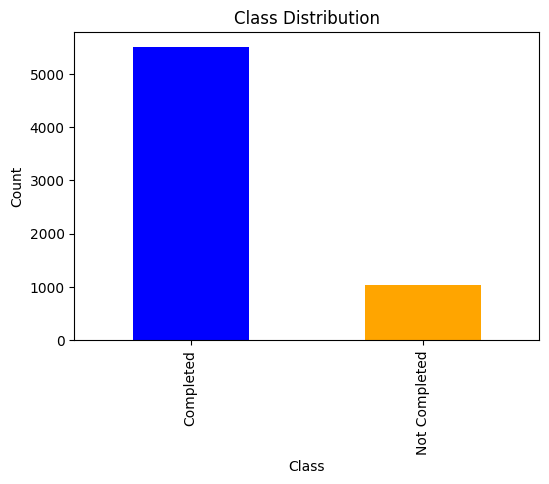

In [ ]:
class_distribution = train_df['Y'].value_counts()

# Plotting the class distribution
plt.figure(figsize=(6, 4))
class_distribution.plot(kind='bar', color=['blue', 'orange'])
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks([0, 1], ['Completed', 'Not Completed'])
plt.show()

We have imbalance dataset

In [ ]:
# splitting data to features and target , test
X = train_df.drop(columns=['Y'])
y = train_df['Y']

X_test = test_df


In [ ]:
print("Training set shape:", X.shape, y.shape)
print("Test set shape:", X_test.shape)

Training set shape: (6548, 27) (6548,)
Test set shape: (818, 27)


## Correlations

In [ ]:
correlation_matrix = X.corrwith(y)
# Select features with high absolute correlation coefficients
relevant_features_corr = correlation_matrix.abs().sort_values(ascending=False).index

In [ ]:
# Train a Random Forest classifier
rf_classifier = RandomForestClassifier()
rf_classifier.fit(X, y)

# Get feature importance scores
feature_importance = pd.Series(rf_classifier.feature_importances_, index=X.columns).sort_values(ascending=False)

# Select top features based on importance scores
relevant_features_importance = feature_importance.index

# Print or return the selected relevant features
print("Top features selected by correlation analysis:", relevant_features_corr[:5])
print("Top features selected by feature importance ranking:", relevant_features_importance[:5])

Top features selected by correlation analysis: Index(['Completed Degree', 'Program Presentation Method', 'طالب',
       'Program Sub Category Code', 'Home City'],
      dtype='object')
Top features selected by feature importance ranking: Index(['Completed Degree', 'University Degree Score', 'Age', 'Start Day',
       'End Day'],
      dtype='object')


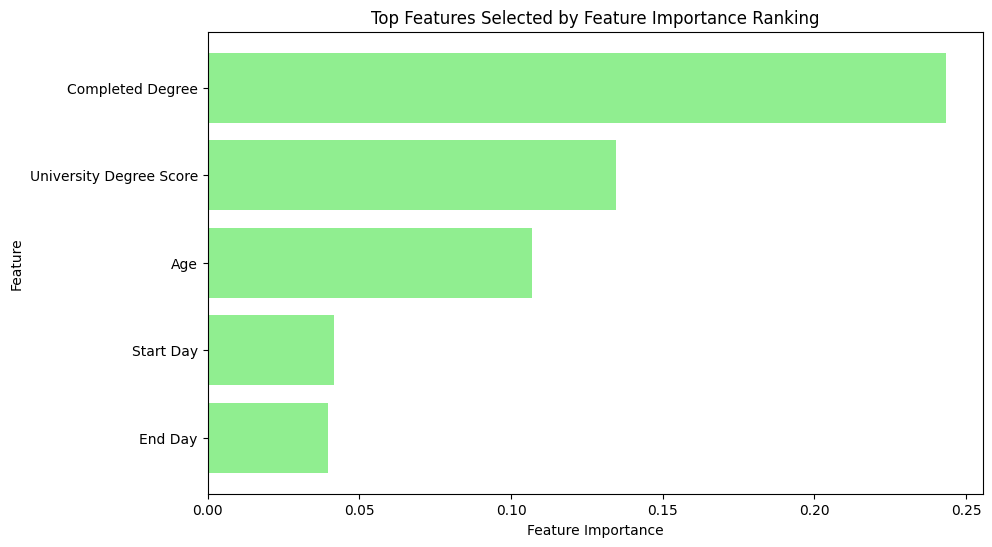

In [ ]:
# Plotting the top features selected by feature importance ranking
plt.figure(figsize=(10, 6))
plt.barh(range(len(relevant_features_importance[:5])), feature_importance[relevant_features_importance[:5]], color='lightgreen')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top Features Selected by Feature Importance Ranking')
plt.yticks(range(len(relevant_features_importance[:5])), relevant_features_importance[:5])
plt.gca().invert_yaxis()
plt.show()

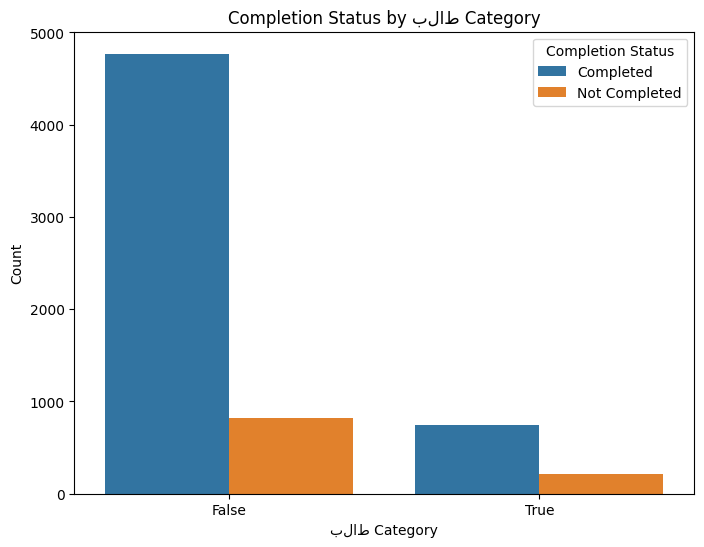

In [ ]:
# Bar chart for 'طالب' column
plt.figure(figsize=(8, 6))
sns.countplot(x='طالب', hue='Y', data=train_df)
plt.title('Completion Status by بلاط Category')
plt.xlabel('بلاط Category')
plt.ylabel('Count')
plt.legend(title='Completion Status', labels=['Completed', 'Not Completed'])
plt.show()

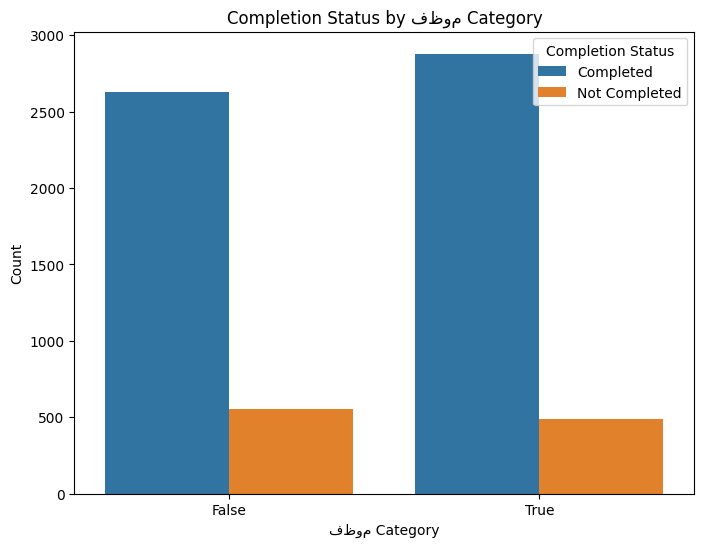

In [ ]:
# Bar chart for 'طالب' column
plt.figure(figsize=(8, 6))
sns.countplot(x='موظف', hue='Y', data=train_df)
plt.title('Completion Status by فظوم Category')
plt.xlabel('فظوم Category')
plt.ylabel('Count')
plt.legend(title='Completion Status', labels=['Completed', 'Not Completed'])
plt.show()

**Top features selected by correlation analysis:**

- 'Completed Degree': This feature has a high correlation (either positive or negative) with the target variable 'Y'. It indicates whether the student completed a university/college degree, which could be strongly associated with program completion.

- 'Program Presentation Method': This feature also shows a significant correlation with the target variable. It represents the presentation method of the program, whether in-person or online.

- "طالب" that is highly correlated with the target variable, it can interpret its influence on program completion accordingly.

**Top features selected by feature importance ranking:**

- 'Completed Degree': Similar to correlation analysis, this feature ranks highly in terms of importance for predicting program completion.

- 'University Degree Score': This feature represents the score of the student in university/college, and it's ranked highly by the model in terms of importance.
- 'Age': The age of the student is also considered important for predicting program completion.

- 'End Day' and 'Start Day': These features likely represent the end and start dates of the program, respectively. They might be important because the duration of the program could influence completion.**


# Bulding the model

## train & validation and data distribution

In [ ]:
# split to train and validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

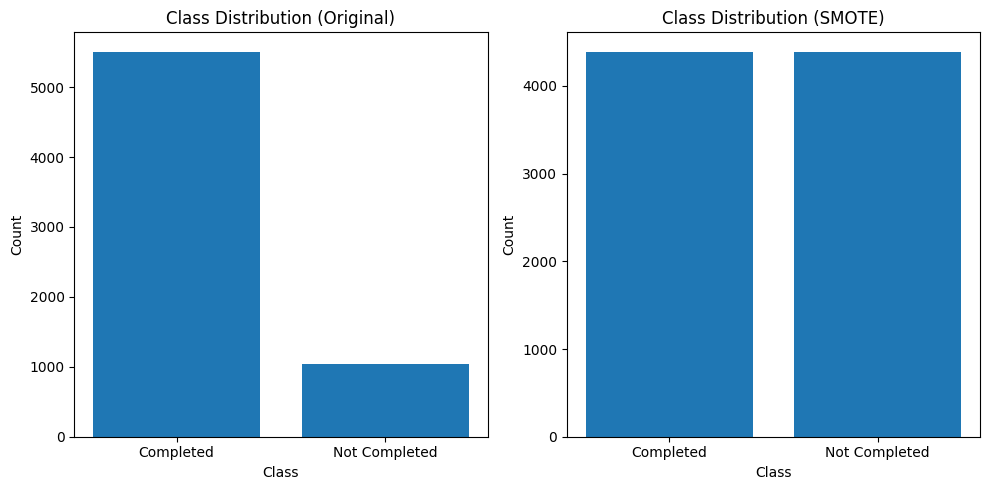

In [ ]:
# Count the number of samples for each class in the original and SMOTE dataset
original_counts = y.value_counts()
smote_counts = y_train_smote.value_counts()

# Plot the class distribution before and after SMOTE
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.bar(original_counts.index, original_counts.values)
plt.title('Class Distribution (Original)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks([0, 1], ['Completed', 'Not Completed'])

plt.subplot(1, 2, 2)
plt.bar(smote_counts.index, smote_counts.values)
plt.title('Class Distribution (SMOTE)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks([0, 1], ['Completed', 'Not Completed'])

plt.tight_layout()
plt.show()


We handle the imbalance using SMOTE :)

## Build decision tree

In [ ]:
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train_smote, y_train_smote)
y_val_pred_dt = decision_tree.predict(X_val)

In [ ]:
# Evaluate the model's performance on the validation set
accuracy_dt = accuracy_score(y_val, y_val_pred_dt)
precision_dt = precision_score(y_val, y_val_pred_dt)
recall_dt = recall_score(y_val, y_val_pred_dt)
f1_dt = f1_score(y_val, y_val_pred_dt)

print("Decision Tree Model Evaluation:")
print("Accuracy:", accuracy_dt)
print("Precision:", precision_dt)
print("Recall:", recall_dt)
print("F1-score:", f1_dt)

Decision Tree Model Evaluation:
Accuracy: 0.8442748091603054
Precision: 0.476
Recall: 0.6197916666666666
F1-score: 0.5384615384615384


In [ ]:
# Making predictions on the test dataset
y_test_pred = decision_tree.predict(X_test)
print("Predictions on test data:", y_test_pred)

Predictions on test data: [1. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 0.
 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 1. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0.
 0. 0. 1. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 1. 0.
 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 1. 0. 1. 0. 0. 0. 1. 0. 

## Tuning for decision tree

In [ ]:
# Define the hyperparameter grid
param_grid_dt = {
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

decision_tree = DecisionTreeClassifier()

# Perform grid search with cross-validation
grid_search_dt = GridSearchCV(estimator=decision_tree, param_grid=param_grid_dt, cv=5, scoring='accuracy')
grid_search_dt.fit(X_train_smote, y_train_smote)

# Get the best hyperparameters
best_params_dt = grid_search_dt.best_params_
print("Best Hyperparameters for Decision Tree:", best_params_dt)

Best Hyperparameters for Decision Tree: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2}


In [ ]:
best_decision_tree = DecisionTreeClassifier(**best_params_dt)
best_decision_tree.fit(X_train_smote, y_train_smote)
y_val_pred_dt = best_decision_tree.predict(X_val)

# Evaluate the model's performance on the validation set
accuracy_dt = accuracy_score(y_val, y_val_pred_dt)
precision_dt = precision_score(y_val, y_val_pred_dt)
recall_dt = recall_score(y_val, y_val_pred_dt)
f1_dt = f1_score(y_val, y_val_pred_dt)

print("Decision Tree Validation Set Evaluation:")
print("Accuracy:", accuracy_dt)
print("Precision:", precision_dt)
print("Recall:", recall_dt)
print("F1-score:", f1_dt)


Decision Tree Validation Set Evaluation:
Accuracy: 0.8603053435114504
Precision: 0.5179282868525896
Recall: 0.6770833333333334
F1-score: 0.5869074492099322


## Build grediant boosting

In [ ]:
gradient_boosting = GradientBoostingClassifier()
gradient_boosting.fit(X_train_smote, y_train_smote)
y_val_pred_gb = gradient_boosting.predict(X_val)

In [ ]:
# Evaluate the model's performance on the validation set
accuracy_gb = accuracy_score(y_val, y_val_pred_gb)
precision_gb = precision_score(y_val, y_val_pred_gb)
recall_gb = recall_score(y_val, y_val_pred_gb)
f1_gb = f1_score(y_val, y_val_pred_gb)

print("Gradient Boosting Validation Set Evaluation:")
print("Accuracy:", accuracy_gb)
print("Precision:", precision_gb)
print("Recall:", recall_gb)
print("F1-score:", f1_gb)

Gradient Boosting Validation Set Evaluation:
Accuracy: 0.8679389312977099
Precision: 0.5353159851301115
Recall: 0.75
F1-score: 0.6247288503253796


In [ ]:
# Making predictions on the test dataset
y_test_pred = gradient_boosting.predict(X_test)
print("Predictions on test data:", y_test_pred)

Predictions on test data: [1. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0.
 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0.
 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 0. 0. 1. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 1. 0. 0. 0. 0. 

## Tuning for Grediant boosting

In [ ]:
# Define hyperparameter grid
param_grid_gb = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.5],
    'max_depth': [3, 5, 7]
}

gradient_boosting = GradientBoostingClassifier()
grid_search_gb = GridSearchCV(estimator=gradient_boosting, param_grid=param_grid_gb, cv=5, scoring='accuracy')
grid_search_gb.fit(X_train_smote, y_train_smote)

# Get best hyperparameters
best_params_gb = grid_search_gb.best_params_
print("Best Hyperparameters for Gradient Boosting:", best_params_gb)

Best Hyperparameters for Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100}


In [ ]:
best_gb_model = grid_search_gb.best_estimator_
y_val_pred_gb = best_gb_model.predict(X_val)

# Evaluate the model's performance on the validation set
accuracy_gb = accuracy_score(y_val, y_val_pred_gb)
precision_gb = precision_score(y_val, y_val_pred_gb)
recall_gb = recall_score(y_val, y_val_pred_gb)
f1_gb = f1_score(y_val, y_val_pred_gb)

print("Evaluation on Validation Set with Best Gradient Boosting Model:")
print("Accuracy:", accuracy_gb)
print("Precision:", precision_gb)
print("Recall:", recall_gb)
print("F1-score:", f1_gb)

Evaluation on Validation Set with Best Gradient Boosting Model:
Accuracy: 0.8839694656488549
Precision: 0.5925925925925926
Recall: 0.6666666666666666
F1-score: 0.627450980392157


## Build random forest

In [ ]:
random_forest = RandomForestClassifier()
random_forest.fit(X_train_smote, y_train_smote)
y_val_pred_rf = random_forest.predict(X_val)

In [ ]:
# Evaluate the model's performance on the validation set
accuracy_rf = accuracy_score(y_val, y_val_pred_rf)
precision_rf = precision_score(y_val, y_val_pred_rf)
recall_rf = recall_score(y_val, y_val_pred_rf)
f1_rf = f1_score(y_val, y_val_pred_rf)

print("Random Forest Validation Set Evaluation:")
print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1-score:", f1_rf)

Random Forest Validation Set Evaluation:
Accuracy: 0.883206106870229
Precision: 0.5924170616113744
Recall: 0.6510416666666666
F1-score: 0.620347394540943


In [ ]:
# Making predictions on the test dataset
y_test_pred = random_forest.predict(X_test)
print("Predictions on test data:", y_test_pred)

Predictions on test data: [1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.
 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 0. 0. 1. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 0. 0. 0. 1. 0. 

## Tuning for random forest

In [ ]:
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_forest = RandomForestClassifier()
grid_search_rf = GridSearchCV(estimator=random_forest, param_grid=param_grid_rf, cv=5, scoring='accuracy')
grid_search_rf.fit(X_train_smote, y_train_smote)

# Get best hyperparameters
best_params_rf = grid_search_rf.best_params_
print("Best Hyperparameters for Random Forest:", best_params_rf)

Best Hyperparameters for Random Forest: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [ ]:
best_rf_model = grid_search_rf.best_estimator_
y_val_pred_rf = best_rf_model.predict(X_val)

accuracy_rf = accuracy_score(y_val, y_val_pred_rf)
precision_rf = precision_score(y_val, y_val_pred_rf)
recall_rf = recall_score(y_val, y_val_pred_rf)
f1_rf = f1_score(y_val, y_val_pred_rf)

# Print evaluation metrics
print("Random Forest Validation Set Evaluation:")
print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1-score:", f1_rf)

Random Forest Validation Set Evaluation:
Accuracy: 0.8954198473282443
Precision: 0.6255707762557078
Recall: 0.7135416666666666
F1-score: 0.6666666666666666


# Results

**Based on the evaluation results of different machine learning models and their hyperparameter tuning, here is the conclusion:**

- Decision Tree:
The decision tree model achieved an accuracy of 84.43% on the validation set before hyperparameter tuning. After tuning, the accuracy improved to 86.03%.

- Gradient Boosting:
The gradient boosting model performed well with an accuracy of 86.79% on the validation set. After hyperparameter tuning, the accuracy was 88.3%.
However, the precision, recall, and F1-score were relatively low compared to other models, indicating a trade-off between precision and recall.

- Random Forest:
The random forest model showed the highest accuracy of 88.3% on the validation set before hyperparameter tuning. After tuning, the accuracy slightly increased to 89.54%.
It also exhibited the highest precision, recall, and F1-score among all models, indicating a better balance between precision and recall.

**Conclusion:**
Random Forest appears to be the most promising model for this dataset, considering its high accuracy and balanced performance in terms of precision and recall.